# Before You Start — Notebooks and the Ideas Behind AI

This course teaches machine learning by running real experiments. This notebook comes before Session 0. It is for anyone who has never opened a notebook, never trained a model, or never written Python. It assumes no background, and you don't have to write any code.

It has two parts. **Part 1** shows how a notebook works and how to follow the code in this course without knowing Python. **Part 2** explains the ideas the rest of the course builds on: what it means for a program to learn from examples, the words you will hear, and what each session is about.

**By the end you should be able to:**

1. open a notebook, run its cells, and recover when a cell fails;
2. follow a code cell from the text around it, its comments and its names, without knowing Python;
3. say how machine learning differs from ordinary programming;
4. use the words *example*, *feature*, *label*, *model*, *training* and *prediction*.

It takes about 45 minutes. Every output is already saved, so you can read it without running anything.

---

# Part 1 — Notebooks

## 1. What a notebook is

A notebook is a document made of **cells**. A **text cell** holds explanation, like this one. A **code cell** holds a few lines of code; when you run it, its result appears just below it. That result is called the cell's **output**: a number, a table or a picture.

The file stores the outputs too. Every notebook in this course arrives with its outputs saved, so you can read it like an article without running anything.

![A mock notebook: a text cell with a heading, a code cell marked [3] with two lines of code, and the output line below it, each labelled on the right.](attachment:prelim-notebook.png)

*Figure P.1 — The three parts of a notebook. The number in brackets beside a code cell records the order in which the cells were run.*
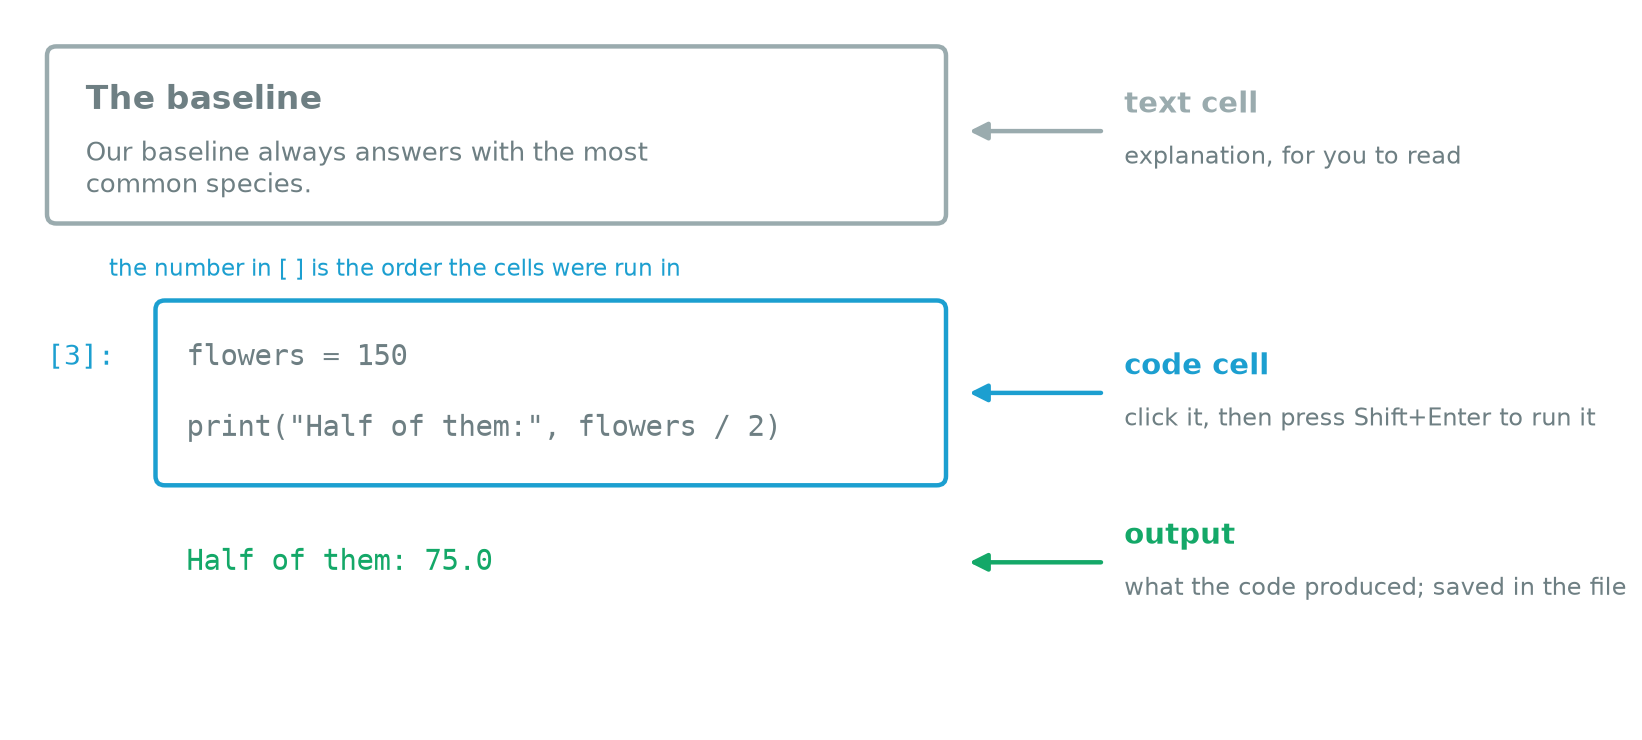

## 2. Opening and running a notebook

There are two ways to open one:

- **Google Colab** needs only a browser and a Google account. Go to colab.research.google.com, choose *File → Upload notebook*, and pick the `.ipynb` file. The code runs on Google's computers, and the libraries Sessions 0–5 need are already installed.
- **On your own computer**, install Python and JupyterLab as the course README describes, type `jupyter lab` in a terminal, and open the file from the list on the left.

To run a code cell, click it and press **Shift+Enter**. The cell runs, its output appears, and the next cell is selected. Try it on the cell below: it adds two numbers.

In [1]:
2 + 3

5

The output is 5. A cell shows the value of its last line, so a notebook also works as a calculator.

## 3. Cells share what they remember

The first cell below stores the number 150 under the name `flowers`. The second cell uses that name.

In [2]:
flowers = 150   # remember the number 150 under the name "flowers"

In [3]:
print("Half of them:", flowers / 2)

Half of them: 75.0


Everything a cell creates stays available to every cell run after it. That is why the cells of a notebook are run **from the top, in order**. If you skip one, a later cell may need something that was never created.

## 4. When a cell fails

If you run the second cell above before the first one, the computer has never heard of `flowers` and stops with an **error**. An error is a block of red text that ends like this:

```
NameError: name 'flowers' is not defined
```

Read the **last line** first: it names the problem. Most errors in this course come from one of three causes:

- **A cell was skipped or run out of order.** Run all the cells above the one that failed: *Runtime → Run before* in Colab, *Run → Run All Above Selected Cell* in JupyterLab.
- **A library is missing**, for example `ModuleNotFoundError: No module named 'torch'`. The setup in the README installs everything the course uses.
- **Something got into a strange state.** Restart and run everything from the top: *Runtime → Restart session* in Colab, *Kernel → Restart Kernel* in JupyterLab.

An error never damages the file. The worst case is running the notebook again from the top.

## 5. Reading code without knowing Python

This course is about ideas, not about a programming language. You can follow every session without writing Python, because no code cell stands alone:

1. **The text before a cell says what it is about to do.** Read it first.
2. **The output shows what happened.** It is the evidence. The text after the cell reads it for you and quotes the numbers that matter.
3. **Comments are plain English.** Anything after a `#` on a line is a note for the reader; the computer ignores it.
4. **Names are chosen to be read.** `X_train` holds the training examples, `predictions` holds the model's answers, `baseline_accuracy` is what its name says.
5. **Cells that only draw a figure can be skipped.** Their code is long, and the picture is what matters. In Session 0 these cells start collapsed.

A few patterns cover most of the lines you will see:

| You see | Read it as |
|---|---|
| `name = ...` | work out the right-hand side and remember it as *name* |
| `print(...)` | show this below the cell |
| `thing.action(...)` | ask *thing* to do *action*, for example `model.fit(...)` |
| `table["petal length (cm)"]` | the column of the table called "petal length (cm)" |
| `import ...` or `from ... import ...` | load a ready-made toolbox; nothing to follow |
| `def name(...):` | define a new command called *name*; the indented lines below it are what the command does |

Here are three lines from Session 0, read this way:

```python
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
model.fit(X_train, y_train)
predictions = model.predict(X_test)
```

- **Line 1:** build a model out of two parts, a scaling step and a model called logistic regression, and call it `model`. The words in brackets are settings; the story doesn't depend on them.
- **Line 2:** train the model (`fit`) on the training examples `X_train` and their answers `y_train`.
- **Line 3:** ask the trained model for its answers on the test examples `X_test`, and keep them as `predictions`.

Those three lines hold the whole idea of machine learning: build a model, train it on examples, use it on new ones. Part 2 explains what that means.

If you later want to write code yourself, the official Python tutorial (docs.python.org/3/tutorial) is a good place to start. This course doesn't need it.

---

# Part 2 — The ideas behind AI

## 6. Rules or examples

An ordinary program follows rules that a person wrote: if the basket is over 50 euros, delivery is free. That works when a person can say what the rules are. Some problems resist it. Nobody can write down the rules that decide whether a photo shows a cat, or whether an email is spam: every rule has exceptions, and the exceptions have exceptions.

**Machine learning** takes a different route. You collect **examples** together with their correct **answers**, and a procedure called **training** finds rules that fit them. The result is a **model**: a program whose rules were found from data instead of written by a person. Once trained, it is used like any other program: new data in, answers out.

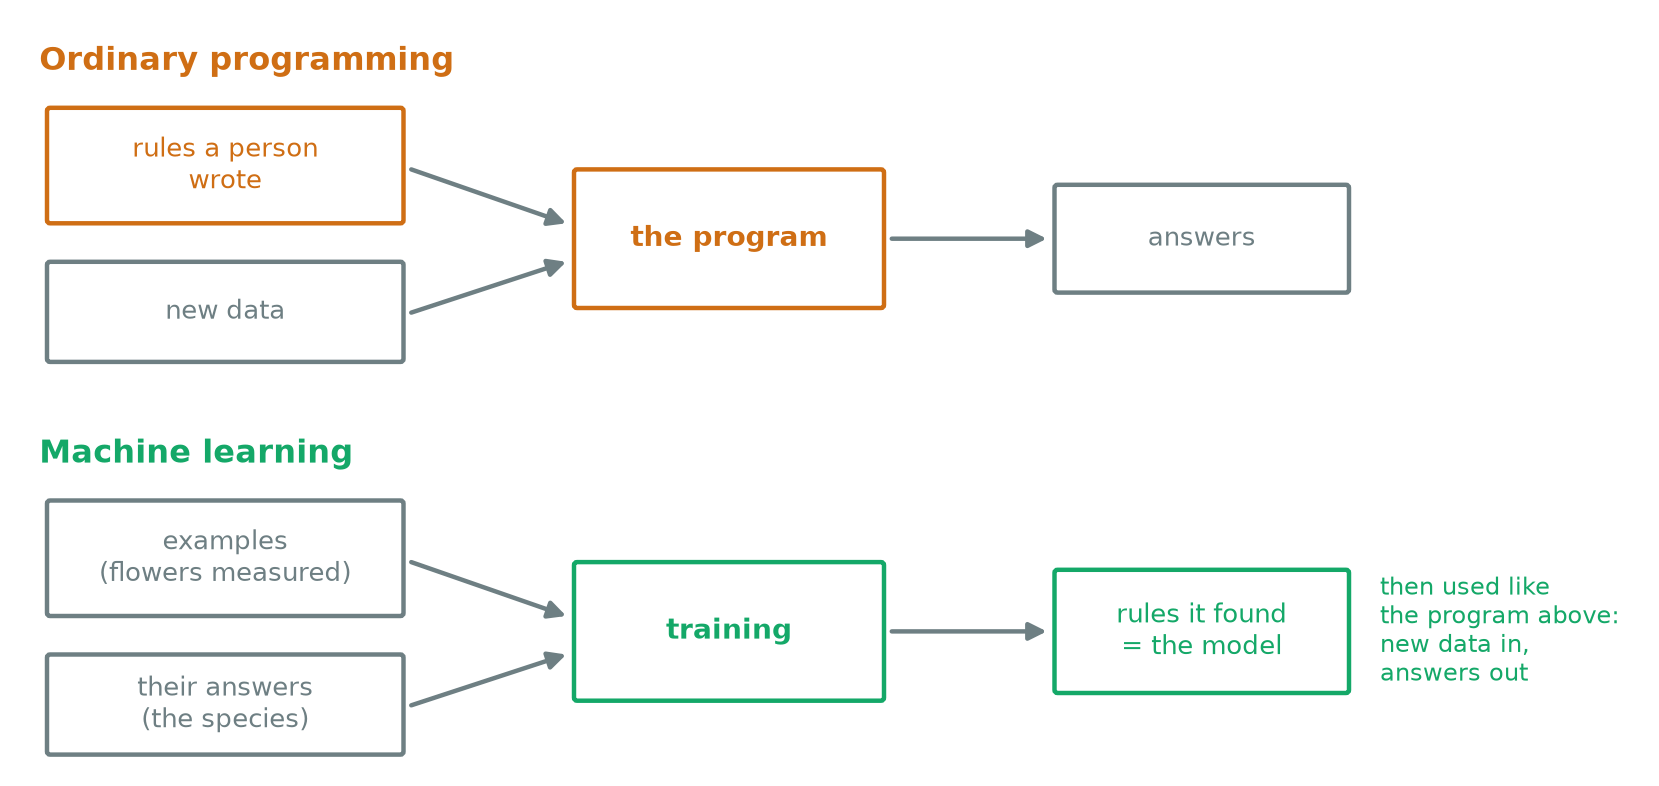

*Figure P.2 — In ordinary programming a person writes the rules. In machine learning, training finds them from examples whose answers are known.*

## 7. You have already used it

Many products you use every day contain a trained model. Each one has the same shape: something goes in, an answer comes out, and the model learned from a large pile of examples.

| Product | What goes in | What comes out | The examples it learned from |
|---|---|---|---|
| Spam filter | an email | spam or not spam | emails that people marked as spam |
| Photo search on a phone | a photo | what is in it: "dog", "beach" | photos labelled by people |
| Recommendations | what you watched or bought | what you might like next | what many other people chose |
| Speech to text | a recording | the words spoken | recordings with their transcripts |
| Chat assistant | the text so far | the next word, again and again | a very large amount of written text |

## 8. The words

Session 0 uses a classic dataset: 150 iris flowers, each measured in four ways, with its species written down by a botanist. Here are five of them:

| sepal length (cm) | sepal width (cm) | petal length (cm) | petal width (cm) | species |
|---|---|---|---|---|
| 5.1 | 3.5 | 1.4 | 0.2 | setosa |
| 4.9 | 3.0 | 1.4 | 0.2 | setosa |
| 7.0 | 3.2 | 4.7 | 1.4 | versicolor |
| 6.4 | 3.2 | 4.5 | 1.5 | versicolor |
| 6.3 | 3.3 | 6.0 | 2.5 | virginica |

The words you will hear, using this table:

- An **example** is one row: one flower.
- The **features** are the inputs, the columns the model is allowed to look at: here the four measurements.
- The **label** is the correct answer for an example: here the species. It is also called the **target**.
- A **model** is the program that turns features into an answer.
- **Training** (also called **fitting**) is the step where the model's rules are set from examples whose labels are known.
- A **prediction** is the model's answer for an example. It can be wrong, which is why the course spends so much time checking predictions.

Predicting a category, such as a species, is called **classification**. Predicting a number, such as a price, is called **regression**.

## 9. Be the learning algorithm

Here is a small learning problem to solve yourself. The cell below lists twelve flowers of two species, versicolor and virginica, with only one feature each: the petal length.

In [4]:
# Twelve flowers: (petal length in cm, species)
examples = [(5.6, "virginica"), (6.4, "virginica"), (4.1, "versicolor"), (4.9, "versicolor"), (4.3, "versicolor"), (4.9, "virginica"),
            (6.1, "virginica"), (3.5, "versicolor"), (4.4, "versicolor"), (5.0, "virginica"), (5.1, "virginica"), (4.0, "versicolor")]
print(len(examples), "flowers")

12 flowers


Virginica petals tend to be longer. So a rule could be: *if the petal is at least some cut-off long, say virginica; otherwise say versicolor.* The cell below checks a cut-off against the twelve flowers and counts the mistakes. It starts at 4.0 cm.

> **Pause:** look at the twelve lengths and pick a better cut-off. How few mistakes can you get? If you are running the notebook, change the `4.0` in the cell below to your cut-off and press Shift+Enter again; try a few.

<details><summary>Answer</summary>

No cut-off gets all twelve right: two of the flowers have petals of exactly 4.9 cm, one versicolor and one virginica, and a rule that only looks at the length must give them the same answer. The best you can do is one mistake. Any cut-off from 4.5 to 5.0 cm does that.

</details>

In [5]:
cut_off = 4.0   # in cm: change this number and run the cell again

mistakes = 0
for length, species in examples:
    guess = "virginica" if length >= cut_off else "versicolor"
    if guess != species:
        mistakes = mistakes + 1
print("Cut-off", cut_off, "cm:", mistakes, "mistakes out of", len(examples))

Cut-off 4.0 cm: 5 mistakes out of 12


With a cut-off of 4.0 cm the rule makes 5 mistakes: every versicolor with a petal of 4.0 cm or more is called virginica.

## 10. What training does

Picking a cut-off by trying values and counting mistakes is what training does, in a very small form. The next cell does it the way a computer would: on all 100 versicolor and virginica flowers in the dataset, it tries every cut-off from 3.0 to 7.0 cm in steps of 0.05 cm and counts the mistakes of each. Its code is collapsed; the picture is the result.

100 flowers. Fewest mistakes: 7, for every cut-off from 4.75 to 4.9 cm


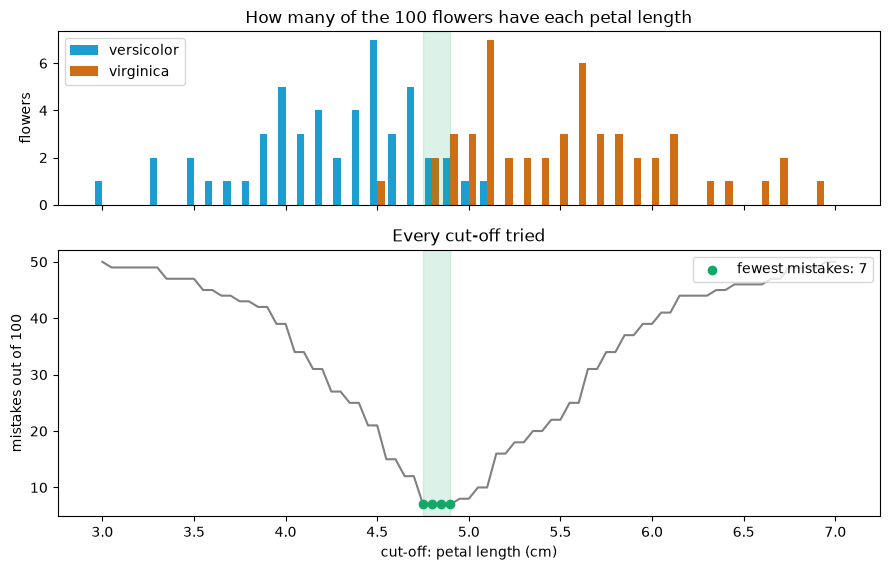

In [6]:
# @title Try every cut-off on 100 flowers and plot the mistakes (code that draws the figure; you can skip it)

from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

iris = load_iris(as_frame=True)
two = iris.target > 0                                        # versicolor (1) and virginica (2)
lengths = iris.data.loc[two, "petal length (cm)"].to_numpy()
is_virginica = (iris.target[two] == 2).to_numpy()
cut_offs = [round(3.0 + 0.05 * i, 2) for i in range(81)]
mistakes = [int(((lengths >= c) != is_virginica).sum()) for c in cut_offs]
fewest = min(mistakes)
best = [c for c, m in zip(cut_offs, mistakes) if m == fewest]
print(f"{len(lengths)} flowers. Fewest mistakes: {fewest}, for every cut-off from {best[0]} to {best[-1]} cm")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.8), sharex=True, gridspec_kw={"height_ratios": [1.3, 2]})
top.hist([lengths[~is_virginica], lengths[is_virginica]], bins=[2.95 + 0.1 * i for i in range(42)], color=["#1C9FD0", "#CF6E14"], label=["versicolor", "virginica"])
top.set(ylabel="flowers", title="How many of the 100 flowers have each petal length")
top.legend(loc="upper left")
bottom.plot(cut_offs, mistakes, color="gray")
bottom.scatter(best, [fewest] * len(best), color="#14A868", zorder=3, label=f"fewest mistakes: {fewest}")
bottom.set(xlabel="cut-off: petal length (cm)", ylabel="mistakes out of 100", title="Every cut-off tried")
bottom.legend(loc="upper right")
for ax in (top, bottom): ax.axvspan(best[0], best[-1], color="#14A868", alpha=0.15)
plt.tight_layout(); plt.show()

*Figure P.3 — Top: how many flowers of each species have each petal length; the two species overlap between about 4.5 and 5.1 cm. Bottom: the number of mistakes for every cut-off. The lowest point, 7 mistakes, is reached by every cut-off from 4.75 to 4.9 cm (green band).*

The curve has a lowest point, and training is the search for it. Three ideas from this picture come back in every session:

- **A model has settings, and training sets them.** This rule has one setting, the cut-off. The model in Session 0 has 15. The networks from Session 6 on have thousands to millions, and large language models have billions. These settings are called the model's **parameters**, or **weights**.
- **Training means making fewer mistakes on the examples.** With one setting the computer can try every value. With millions it can't, so it changes all of them a little at a time, each time in the direction that reduces the mistakes. Session 6 shows how. The number it tries to reduce is called the **loss**.
- **Even the best setting makes mistakes here.** The species overlap on petal length, so 7 mistakes is the floor for this rule. Using more features can help: Session 0 uses all four measurements.

One question is still open. The cut-off was chosen by looking at these 100 flowers. Will it work as well on flowers it has never seen? That is the question Session 0 starts with, and the reason it hides part of the data.

## 11. AI, machine learning, deep learning, generative AI

You will hear these four terms used loosely. Each one is a special case of the one before it:

- **Artificial intelligence** is the umbrella: programs that do things that seem to need intelligence. Not all of it learns. The route planner in a map app finds the shortest way with a search procedure that people wrote by hand.
- **Machine learning** is AI that learns its rules from examples. Sessions 0–5.
- **Deep learning** is machine learning with **neural networks**: models built from many simple units in layers. Sessions 6–11.
- **Generative AI** is deep learning that produces new text, images or code. A **large language model** (LLM), the kind behind chat assistants, is one. Sessions 10–12.

Most of the course is **supervised learning**: every example comes with its label, as in the flower table. Session 5 covers **unsupervised learning**, where there are no labels and the model looks for groups by itself.

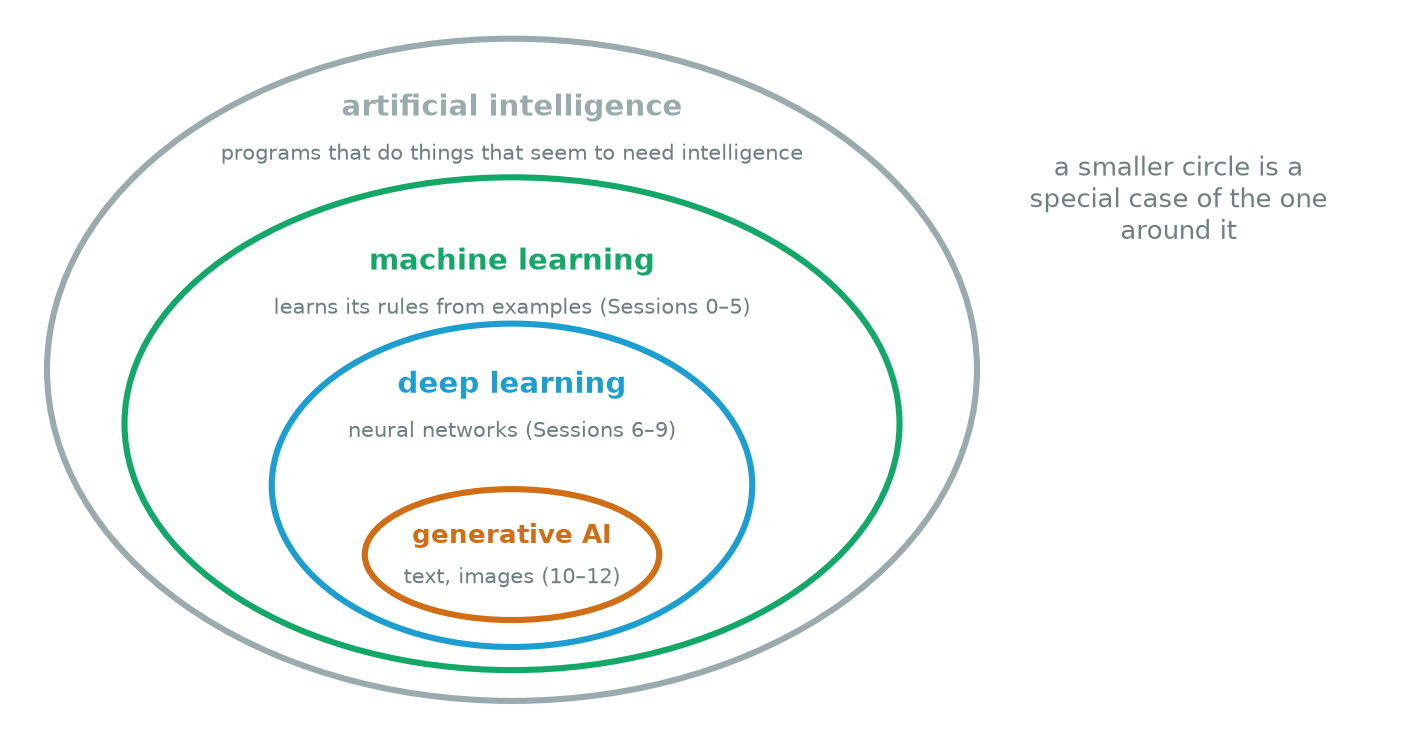

*Figure P.4 — The four terms as circles within circles. The course starts in the machine learning ring and moves inwards.*

## 12. What a model can't do by itself

Four warnings the course comes back to, each shown with a real result:

- **A model only knows its examples.** If the examples are wrong, incomplete, or unlike the cases it will meet, the model will be too, and it won't say so. Session 1 is about reading data before trusting it.
- **A score means little without a comparison.** In Session 0, a "model" that always gives the same answer is already right 0.316 of the time. Session 4 starts with a model that scores 99% and is useless.
- **A model can look perfect by cheating.** In Session 2, a column that gives away the answer pushes the accuracy to 1.000.
- **A learned model is not automatically better than a person's rule.** In Session 0, a two-line rule written by hand scores 0.947 and the model 0.921.

## 13. The course at a glance

Sessions 0–5 work on small tables of data with **scikit-learn**, a library of ready-made models. Sessions 6–9 move to neural networks with **PyTorch**, a library for building and training them. Sessions 10–12 are about text and language models.

| Session | Title | The question it answers |
|---|---|---|
| 0 | Teaching a Machine from Examples | How do you run one honest experiment, and how do you know the model is any good? |
| 1 | Reading a Dataset | What can be wrong with a table of data before any model sees it? |
| 2 | Preprocessing and Leakage | How do you turn a table into numbers without letting the answer leak in? |
| 3 | Four Ways to Draw a Boundary | How do different kinds of model behave on the same problem? |
| 4 | Evaluation: When Is a Model Good? | When can you trust a score? |
| 5 | Finding Structure Without Labels | What can you learn from data that has no answers? |
| 6 | From a Linear Model to a Neural Network | How does a model actually learn, step by step? |
| 7 | Training a Neural Network: Reading the Curves | Training went badly: how do you find out why? |
| 8 | Computer Vision | Why do images need a different kind of network? |
| 9 | Transfer Learning | How do you reuse a network that someone else trained? |
| 10 | How Text Becomes Numbers | How does a computer read text? |
| 11 | Attention | How does a model work out which words matter to each other? |
| 12 | Language Models in Systems | How do you build something useful around a language model, and how does it go wrong? |

## 14. How each session works

- A session takes about 60 minutes. The numbered sections are the main path. The **Going deeper** part at the end is optional reading after the session, and it is where the maths lives.
- **Pause** boxes ask a question before the answer appears. Decide on your answer before you scroll on: a guess made first, even a wrong one, makes the answer easier to remember.
- Every number quoted in the text comes from the saved outputs. If you run a notebook yourself, some numbers may come out slightly different.
- Every experiment follows the same five steps: split the data, set a baseline, train a model, evaluate it, read its mistakes. Session 0 introduces them, and that is where to go next.